# Rotation Decision Support
Compare the current rotation with two alternatives using supplied NASA weather and vegetation data, local soil inputs, crop characteristics and farmer priorities. Weather outlooks support the comparison; they do not predict treatment benefits.

**Data cutoffs differ:** the state-temperature workbook extends through 2025 and supports a 2026 temperature outlook. POWER ends in 2024 and supports the separate 2025 weather experiment. Neither is a current 2027 forecast. The workbook is attributed to NASA by its supplier; its original export metadata is still needed to verify provenance and the inferred January–December/Celsius schema.

In [1]:
from pathlib import Path
import sys
import pandas as pd
import matplotlib.pyplot as plt
ROOT = Path.cwd()
if not (ROOT/'year_outlook.py').exists(): ROOT = ROOT/'Crop_Protection_Tool'/'legacy'
sys.path.insert(0,str(ROOT))
from year_outlook import run, LABELS
monthly, performance, outlook, test, validation = run(ROOT.parent/'data/power_daily.csv')
display(performance.round(3))

     target   selected_model  test_MAE  baseline_MAE  skill_vs_baseline  test_band_coverage  test_months  validation_band_halfwidth                        interpretation
tmax_mean_c Seasonal average     2.183         2.183              0.000               0.875           48                      4.093 No added skill over seasonal baseline
    rain_mm   Season + trend    25.722        27.527              0.066               0.938           48                     62.295    Added skill observed on test years
   hot_days   Season + trend     0.565         0.521             -0.086               0.854           48                      1.951 No added skill over seasonal baseline
max_dry_run Seasonal average     3.437         3.437              0.000               0.938           48                      9.375 No added skill over seasonal baseline


## Your state-temperature workbook is now an input
The original Excel file is included in data/. Select a state and a representative location within it. This selects the nearest grid point carrying that state label, not a statewide average. T2M is monthly mean air temperature, distinct from daily Tmax. The workbook lacks explicit monthly column headings; January–December and Celsius are declared assumptions.

{'state': 'IOWA', 'selected_lat': 42.0, 'selected_lon': -93.75, 'source': 'User-provided 2000–2025 USA Temp by State workbook, attributed by user to NASA', 'schema': 'Columns 6–17 interpreted as January–December monthly mean T2M; Celsius assumed. Original export metadata not supplied.', 'meaning': 'Representative grid point within the state label; not a state-wide average and not daily maximum temperature.', 'model': 'Seasonal average', 'test_MAE_c': 1.6768883501160672, 'baseline_MAE_c': 1.6768883501160672, 'skill_vs_baseline': 0.0, 'test_months': 60}
      date  predicted_monthly_mean_t2m_c  lower_band  upper_band
2026-01-01                         -6.40      -10.40       -2.40
2026-02-01                         -4.48       -8.48       -0.48
2026-03-01                          3.06       -0.94        7.06
2026-04-01                          9.82        5.82       13.82
2026-05-01                         16.29       12.29       20.29
2026-06-01                         22.14       18.14

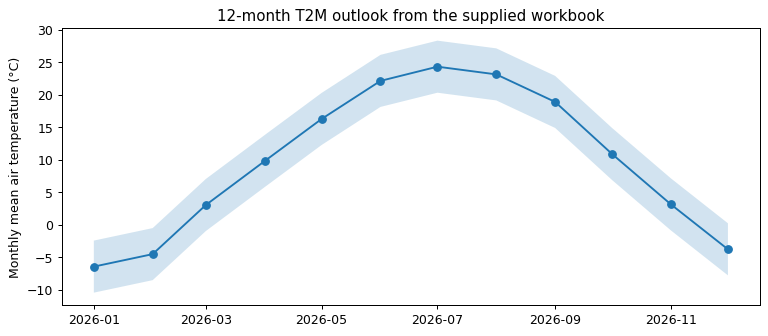

In [2]:
from state_temperature import run_state
STATE='IOWA'
LATITUDE=42.03
LONGITUDE=-93.62
state_history,state_outlook,state_test,state_info=run_state(STATE,LATITUDE,LONGITUDE)
print(state_info)
display(state_outlook.round(2))
_, ax=plt.subplots(figsize=(10,4))
ax.plot(state_outlook.date,state_outlook.predicted_monthly_mean_t2m_c,marker='o')
ax.set(ylabel='Monthly mean air temperature (°C)',title='12-month T2M outlook from the supplied workbook')
ax.fill_between(state_outlook.date,state_outlook.lower_band,state_outlook.upper_band,alpha=.2)
plt.show()
out=ROOT.parent/'outputs';out.mkdir(exist_ok=True)
state_outlook.to_csv(out/'state_temperature_outlook.csv',index=False)
state_test.to_csv(out/'state_temperature_test.csv',index=False)

## Local soil, intended crops and farmer priorities
Enter actual measurements or local soil-map attributes. Unknown values remain unknown; regional weather cannot supply them. Example strategy choices below need local agronomic review. Farmer priorities determine the discussion focus, not an unvalidated numerical ranking.

In [3]:
SOIL={'texture':'Unknown','drainage':'Unknown','organic_matter_percent':None,'available_water_capacity_mm':None,'source':'Not supplied'}
DESIRED_CROPS=['Corn','Soybean']
FARMER_PRIORITIES=['Conserve water','Maintain soil cover']
CONSTRAINTS={'irrigation':'Rainfed','can_establish_cover':None,'small_grain_market':None,'extra_equipment_available':None}
print('Soil inputs:',SOIL)
print('Desired crops:',DESIRED_CROPS,'Priorities:',FARMER_PRIORITIES)
missing=[k for k,v in SOIL.items() if v is None or v=='Unknown']
print('Local soil information still needed:',missing)

Soil inputs: {'texture': 'Unknown', 'drainage': 'Unknown', 'organic_matter_percent': None, 'available_water_capacity_mm': None, 'source': 'Not supplied'}
Desired crops: ['Corn', 'Soybean'] Priorities: ['Conserve water', 'Maintain soil cover']
Local soil information still needed: ['texture', 'drainage', 'organic_matter_percent', 'available_water_capacity_mm']


## Rotation comparison connected to the challenge
The alternatives retain the intended corn/soybean crops across the sequence. Soil-cover and diversification benefits are potential roles grounded in extension guidance, not predicted outcomes. No strategy is declared best while local suitability, costs and soil information remain unknown.

In [4]:
comparison=pd.DataFrame([
 {'Strategy':'Current: corn → soybean','Potential soil role':'Baseline; cover depends on residues and management','Water and weather review':'Review heat/rainfall exposure at pollination and reproductive stages','Fit to priorities':'Maintains familiar sequence','Local checks':'Soil drainage, residues, crop stage, water access','Status':'Baseline; field practices need confirmation'},
 {'Strategy':'Corn → soybean with winter rye cover','Potential soil role':'Potential extra living cover and post-termination residue [ISU cover crops]','Water and weather review':'Living rye uses water; assess spring moisture and termination [NRCS]','Fit to priorities':'Relevant to soil-cover priority; water trade-off needs review','Local checks':'Establishment window, soil moisture, equipment and termination capacity','Status':'Needs local feasibility review'},
 {'Strategy':'Corn → soybean → oats/legume → corn','Potential soil role':'Explore a different crop family and additional cover opportunities','Water and weather review':'Assess timing against local heat/rain history; water benefits not quantified','Fit to priorities':'Relevant to diversification; additional market and equipment needs','Local checks':'Local crop suitability, market, equipment, disease and soil constraints','Status':'Needs local feasibility review'}
])
if CONSTRAINTS['can_establish_cover'] is False: comparison.loc[1,'Status']='Outside stated establishment constraint'
if CONSTRAINTS['small_grain_market'] is False: comparison.loc[2,'Status']='Market constraint: explore non-sale use or another locally suitable alternative'
display(comparison)
print('Current priority focus:', ', '.join(FARMER_PRIORITIES))
if SOIL['drainage']=='Poor':print('Poor drainage reported: review establishment and field trafficability locally. Rainfall alone cannot quantify waterlogging.')
if SOIL['available_water_capacity_mm'] is None:print('No measured soil water capacity: irrigation needs and crop-water deficits cannot be calculated.')
comparison.to_csv(ROOT.parent/'outputs/rotation_decision_table.csv',index=False)

                            Strategy                                                         Potential soil role                                                     Water and weather review                                                  Fit to priorities                                                            Local checks                                      Status
             Current: corn → soybean                          Baseline; cover depends on residues and management         Review heat/rainfall exposure at pollination and reproductive stages                                        Maintains familiar sequence                       Soil drainage, residues, crop stage, water access Baseline; field practices need confirmation
Corn → soybean with winter rye cover Potential extra living cover and post-termination residue [ISU cover crops]         Living rye uses water; assess spring moisture and termination [NRCS]      Relevant to soil-cover priority; water trade-off needs revi

## First check: does the model beat a simple seasonal average?
Positive skill means lower MAE than the baseline on 2021–2024. Zero or negative skill means no demonstrated added predictive value. These are four forecast years, so estimates are uncertain. Model selection used earlier years only.

In [5]:
for r in performance.itertuples():
    print(f'{LABELS[r.target]}: {r.interpretation}. MAE={r.test_MAE:.2f}; baseline={r.baseline_MAE:.2f}; skill={r.skill_vs_baseline:.1%}')
lead = test.groupby(['target','lead_month']).absolute_error.mean().unstack(0)
display(lead.round(2))

Monthly mean of daily maximum temperature (°C): No added skill over seasonal baseline. MAE=2.18; baseline=2.18; skill=0.0%
Monthly rainfall total (mm): Added skill observed on test years. MAE=25.72; baseline=27.53; skill=6.6%
Monthly days ≥35°C: No added skill over seasonal baseline. MAE=0.57; baseline=0.52; skill=-8.6%
Longest within-month run <1 mm/day (days): No added skill over seasonal baseline. MAE=3.44; baseline=3.44; skill=0.0%
 hot_days  max_dry_run  rain_mm  tmax_mean_c
     0.05         3.25    15.30         1.18
     0.05         2.76    28.67         4.59
     0.05         2.10    12.28         2.20
     0.05         3.67    25.70         1.45
     0.10         3.53    40.82         1.27
     1.00         2.42    23.84         1.84
     2.08         4.67    27.19         1.37
     2.22         2.79    15.16         2.04
     1.03         4.09    42.74         2.85
     0.05         4.30    35.26         2.99
     0.05         5.32    26.13         1.31
     0.05         2.

## Your crop and priorities
Enter months corresponding to locally observed or expected sensitive stages. The tool cannot infer these from the available data. These inputs select which forecast months deserve attention; they do not change the regional weather.

In [6]:
CROP = 'Corn'  # Corn or Soybean; other crops need local guidance
SENSITIVE_MONTHS = [6, 7, 8]  # illustrative; change with local stage information
WATER_ACCESS = 'Rainfed'  # Rainfed or Irrigated
PRIORITY = 'Conserve water and protect soil'
assert SENSITIVE_MONTHS and all(1 <= x <= 12 for x in SENSITIVE_MONTHS)
print(CROP, WATER_ACCESS, PRIORITY)

Corn Rainfed Conserve water and protect soil


## Twelve-month outlook with empirical uncertainty bands
The shaded range is based on past validation errors, pooled across months. It is not a guaranteed or month-specific probability interval. An expected count of hot days does not identify the dates on which heat will occur.

     target       date  lead_month  prediction  lower_band  upper_band            model  test_skill_vs_baseline                                                           status
tmax_mean_c 2025-06-01           6       27.79       23.70       31.88 Seasonal average                    0.00 Statistical outlook; empirical band, not a live weather forecast
tmax_mean_c 2025-07-01           7       29.97       25.88       34.06 Seasonal average                    0.00 Statistical outlook; empirical band, not a live weather forecast
tmax_mean_c 2025-08-01           8       29.19       25.09       33.28 Seasonal average                    0.00 Statistical outlook; empirical band, not a live weather forecast
    rain_mm 2025-06-01           6      102.85       40.55      165.14   Season + trend                    0.07 Statistical outlook; empirical band, not a live weather forecast
    rain_mm 2025-07-01           7       84.25       21.96      146.55   Season + trend                    0.07 Sta

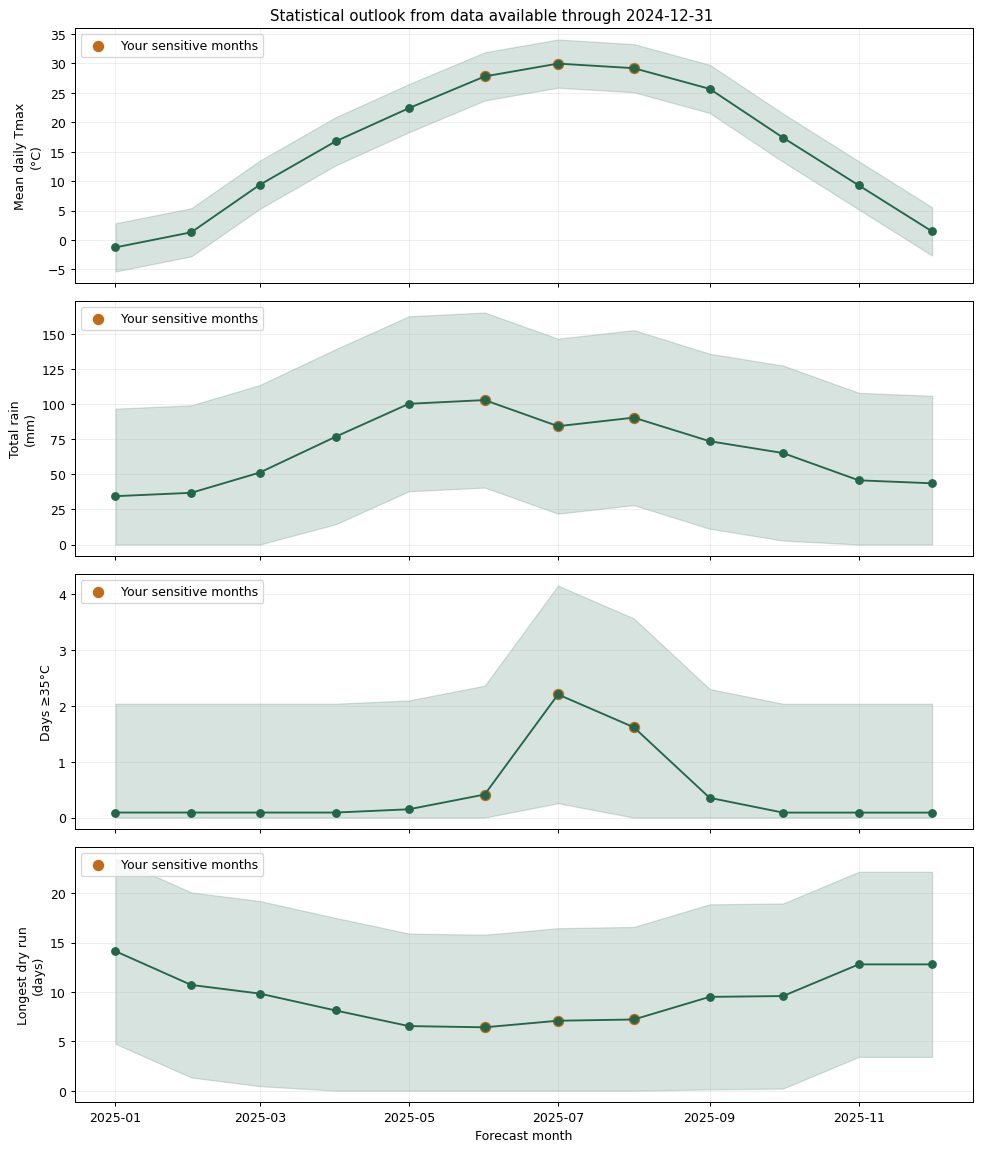

In [7]:
fig, axes = plt.subplots(4,1,figsize=(11,13),sharex=True)
for ax,(target,label) in zip(axes,LABELS.items()):
    f=outlook[outlook.target==target].copy()
    ax.plot(f.date,f.prediction,marker='o',color='#24664a')
    ax.fill_between(f.date,f.lower_band,f.upper_band,alpha=.18,color='#24664a')
    marked=f[f.date.dt.month.isin(SENSITIVE_MONTHS)]
    ax.scatter(marked.date,marked.prediction,color='#c16b18',s=65,label='Your sensitive months')
    ax.set_ylabel({'tmax_mean_c':'Mean daily Tmax\n(°C)','rain_mm':'Total rain\n(mm)','hot_days':'Days ≥35°C','max_dry_run':'Longest dry run\n(days)'}[target]);ax.grid(alpha=.2);ax.legend(loc='upper left')
axes[-1].set_xlabel('Forecast month');fig.suptitle('Statistical outlook from data available through '+str(monthly.index.max().to_period("M").end_time.date()))
plt.tight_layout();plt.show()
display(outlook[outlook.date.dt.month.isin(SENSITIVE_MONTHS)].round(2))

## Compare protection strategies while keeping the desired crop
These are options to discuss, not predicted treatment effects. No option receives a fabricated yield or risk-reduction percentage.

In [8]:
strategies=pd.DataFrame([
 {'Strategy':'Current sequence and practice','Potential role':'Baseline for comparison','Local checks':'Record crop history, soil texture, water access and actual crop stage'},
 {'Strategy':'Current crop with winter cover in the rotation','Potential role':'Potential cover and residue contributions between crops','Local checks':'Living cover uses water; verify establishment, soil moisture and termination timing [NRCS; ISU]'},
 {'Strategy':'Diversify with a small grain/legume between returns to the desired crop','Potential role':'Explore more seasonal cover and a different sequence','Local checks':'Check equipment, market, crop suitability, disease constraints and realistic calendar; benefits not quantified'}
])
display(strategies)
if CROP.lower()=='corn':
    print('Corn: inspect stage around tasseling/silking. Pollination is sensitive to water stress [ISU corn pollination].')
elif CROP.lower()=='soybean':
    print('Soybean: confirm reproductive stage, especially R3–R6 [ISU soybean drought].')
else:
    print('No crop-specific protection rule is available for this crop. Obtain local evidence.')
print('Check soil moisture and field symptoms. These inputs do not determine irrigation quantities or crop damage.')

                                                               Strategy                                          Potential role                                                                                                   Local checks
                                          Current sequence and practice                                 Baseline for comparison                                          Record crop history, soil texture, water access and actual crop stage
                         Current crop with winter cover in the rotation Potential cover and residue contributions between crops                Living cover uses water; verify establishment, soil moisture and termination timing [NRCS; ISU]
Diversify with a small grain/legume between returns to the desired crop    Explore more seasonal cover and a different sequence Check equipment, market, crop suitability, disease constraints and realistic calendar; benefits not quantified
Corn: inspect stage around tasseling/silking

## Satellite context: quality-filtered 2024 vegetation
This single pixel is not verified as a farm parcel. NDVI is not a direct soil-health measurement. It is excluded from forecast predictors because just one year is available.

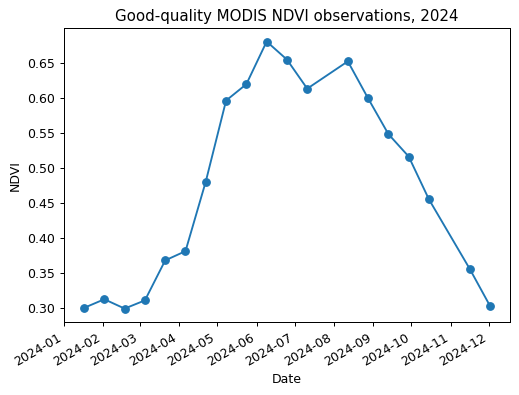

In [9]:
m=pd.read_csv(ROOT.parent/'data/modis_2024.csv')
m['Date']=pd.to_datetime(m.Date)
n='MOD13Q1_061__250m_16_days_NDVI';q='MOD13Q1_061__250m_16_days_pixel_reliability'
g=m[(m.Date.dt.year==2024)&(m[q]==0)].copy()
g.plot(x='Date',y=n,marker='o',legend=False,title='Good-quality MODIS NDVI observations, 2024',ylabel='NDVI');plt.show()

## Export and sources
Full sources and SI disclosure are in SOURCES.md. Keep the model limits with exported predictions.

In [10]:
out=ROOT.parent/'outputs';out.mkdir(exist_ok=True)
performance.to_csv(out/'performance.csv',index=False)
outlook.to_csv(out/'next_12_months.csv',index=False)
test.to_csv(out/'heldout_predictions.csv',index=False)
strategies.to_csv(out/'protection_strategies.csv',index=False)
fig.savefig(out/'12_month_outlook.png',dpi=160,bbox_inches='tight')
print('Saved to',out.resolve())

Saved to /workspace/scratch/f6a0ffe2bc9b/Crop_Protection_Tool/outputs
